# MeterTrace — Notebook 04: Machine Learning Baselines

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 4 of 8

## Purpose
Train three simple, classical models on the 11 engineered features from Notebook 03. They are the
**baselines** that the deep learning models in Notebook 05 must beat.

| Model | Type | Trained on | Output |
|---|---|---|---|
| Logistic Regression | Supervised | All training customers, with labels | Theft probability |
| Random Forest | Supervised | All training customers, with labels | Theft probability |
| Isolation Forest | Unsupervised | **Normal** training customers only, **without** labels as targets | Anomaly score (higher = more unusual) |

## Rules followed in this notebook
- We load the **existing** feature files from Notebook 03 (same customers, same row order) and select
  inputs with the saved `feature_columns` list. `FLAG` and `CONS_NO` are **never** model inputs.
- Everything that is fitted (the scaler and all three models) is fitted on **training customers only**.
- We compare the models on **validation** customers only.
- **The test file is not even loaded here.** Test customers stay untouched until Notebook 06, which will
  load the saved models, choose thresholds on validation data, and score the test set once.
- We do **not** choose decision thresholds here. ROC-AUC and PR-AUC measure how well a model *ranks*
  customers, so they need no threshold.

## Outputs
- `models/logistic_regression.joblib`, `models/random_forest.joblib`, `models/isolation_forest.joblib`
  (git-ignored; re-create them by re-running this notebook)
- `outputs/results/04_validation_scores.csv`: every validation customer's score from each model (committed)
- `outputs/results/04_validation_metrics.csv`, `outputs/results/04_logistic_regression_coefficients.csv`
- `outputs/figures/04_validation_comparison.png`

## 0. Setup

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, recall_score

In [2]:
# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
for folder in [MODEL_DIR, FIGURE_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Constants ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

features_metadata = json.loads((PROCESSED_DIR / "features_metadata.json").read_text())
FEATURE_COLUMNS = features_metadata["feature_columns"]
LABEL_COLUMN = features_metadata["label_column"]

NORMAL_COLOR = "#2a78d6"
THEFT_COLOR = "#eb6834"
NEUTRAL_COLOR = "#52514e"
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]   # LR, RF, IF (fixed order)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Feature columns (from Notebook 03):", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)

Feature columns (from Notebook 03): 11
['mean_kwh', 'median_kwh', 'std_kwh', 'max_kwh', 'zero_ratio', 'missing_ratio', 'volatility', 'longest_zero_run_days', 'spike_frequency', 'drop_frequency', 'consumption_change']


## 1. Load the training and validation features
Only two of the three feature files are loaded. The test file stays on disk, unopened.

In [3]:
train_table = pd.read_parquet(PROCESSED_DIR / "features_train.parquet")
validation_table = pd.read_parquet(PROCESSED_DIR / "features_validation.parquet")

X_train = train_table[FEATURE_COLUMNS]
y_train = train_table[LABEL_COLUMN].to_numpy()
X_validation = validation_table[FEATURE_COLUMNS]
y_validation = validation_table[LABEL_COLUMN].to_numpy()

print("X_train:", X_train.shape, "| theft:", int(y_train.sum()), f"({y_train.mean():.2%})")
print("X_validation:", X_validation.shape, "| theft:", int(y_validation.sum()), f"({y_validation.mean():.2%})")
print("Label or ID among the inputs?", LABEL_COLUMN in X_train.columns or "CONS_NO" in X_train.columns)
print("No customer in both files:", len(set(train_table.index) & set(validation_table.index)) == 0)

X_train: (29657, 11) | theft: 2530 (8.53%)
X_validation: (6354, 11) | theft: 540 (8.50%)
Label or ID among the inputs? False
No customer in both files: True


## 2. Why accuracy is misleading here
Only about 8.5% of customers are labelled theft. A "model" that simply predicts **normal for everyone**
looks excellent on accuracy, yet it never finds a single theft case. We check this on the validation set.

In [4]:
predict_everyone_normal = np.zeros_like(y_validation)

print(f"Accuracy of 'everyone is normal': {accuracy_score(y_validation, predict_everyone_normal):.2%}")
print(f"Recall (theft cases found):       {recall_score(y_validation, predict_everyone_normal):.2%}")

Accuracy of 'everyone is normal': 91.50%
Recall (theft cases found):       0.00%


That is why we use metrics that focus on **ranking theft customers above normal ones**:

- **ROC-AUC**: the probability that a randomly chosen theft customer gets a higher score than a randomly
  chosen normal customer. 0.5 = random, 1.0 = perfect.
- **PR-AUC** (average precision): summarises precision and recall across all possible cut-offs. It is more
  demanding with imbalanced data. A random ranking scores about the **theft share** (about 0.085), not 0.5.

Neither metric needs a decision threshold, so we can compare models now and leave thresholds to Notebook 06.

As a reference point we also score the simplest possible ranking: **`mean_kwh` on its own**, with no
training (the report's "average consumption" baseline, here on validation customers).

In [5]:
reference_auc = roc_auc_score(y_validation, X_validation["mean_kwh"])
reference_pr_auc = average_precision_score(y_validation, X_validation["mean_kwh"])
random_pr_auc = y_validation.mean()

print(f"Average consumption alone (validation): ROC-AUC = {reference_auc:.4f}, PR-AUC = {reference_pr_auc:.4f}")
print(f"Random ranking (validation):            ROC-AUC = 0.5000, PR-AUC ≈ {random_pr_auc:.4f}")

Average consumption alone (validation): ROC-AUC = 0.6671, PR-AUC = 0.1897
Random ranking (validation):            ROC-AUC = 0.5000, PR-AUC ≈ 0.0850


## 3. Model 1 — Logistic Regression
Logistic Regression multiplies each feature by a weight (coefficient), adds them up, and turns the sum
into a probability between 0 and 1.

- **Scaling:** features have very different units (kWh, days, ratios). A `StandardScaler` rescales each
  feature to mean 0 and standard deviation 1. It is placed **inside a `Pipeline`**, so calling `fit` on
  training data fits the scaler on **training customers only**. Validation data is only *transformed* with
  the training mean and standard deviation.
- **Class imbalance:** `class_weight="balanced"` makes each theft customer count about 11 times as much as
  a normal customer during training, so the model cannot ignore the minority class.
- **Hyperparameters:** scikit-learn defaults (L2 regularisation, `C=1.0`). `max_iter=1000` only gives the
  solver enough steps to converge.

In [6]:
logistic_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])

start_time = time.perf_counter()
logistic_regression.fit(X_train, y_train)
lr_training_seconds = time.perf_counter() - start_time

lr_validation_probability = logistic_regression.predict_proba(X_validation)[:, 1]
lr_train_probability = logistic_regression.predict_proba(X_train)[:, 1]

print(f"Training time: {lr_training_seconds:.2f} s | iterations used: {logistic_regression.named_steps['model'].n_iter_[0]}")
print(f"Train      ROC-AUC = {roc_auc_score(y_train, lr_train_probability):.4f}")
print(f"Validation ROC-AUC = {roc_auc_score(y_validation, lr_validation_probability):.4f}, "
      f"PR-AUC = {average_precision_score(y_validation, lr_validation_probability):.4f}")

Training time: 0.06 s | iterations used: 19
Train      ROC-AUC = 0.7310
Validation ROC-AUC = 0.7216, PR-AUC = 0.2377


### Reading the coefficients carefully
Because the features were standardised, each coefficient means: *how much the log-odds of theft change
when this feature increases by one standard deviation, **while all other features stay the same***.

**Caution:** Notebook 03 showed that several features move together, for example `zero_ratio` and
`longest_zero_run_days` (Spearman 0.98), `mean_kwh` and `median_kwh` (0.96), and `std_kwh` and `max_kwh`
(0.95). "All other features stay the same" is unrealistic for such pairs. The model can split their shared
effect between them in arbitrary ways, sometimes giving one a large positive weight and its partner a
negative one. So:

- read the coefficients of correlated features **together**, not one by one;
- a negative sign does **not** necessarily mean "this feature protects against theft";
- use coefficients to describe *this* model, not as proof of cause and effect.

In [7]:
lr_coefficients = pd.DataFrame({
    "coefficient (per 1 std)": logistic_regression.named_steps["model"].coef_[0],
}, index=FEATURE_COLUMNS)
lr_coefficients["odds multiplier (per 1 std)"] = np.exp(lr_coefficients["coefficient (per 1 std)"])
lr_coefficients = lr_coefficients.sort_values("coefficient (per 1 std)", ascending=False).round(3)
lr_coefficients.to_csv(RESULTS_DIR / "04_logistic_regression_coefficients.csv")
lr_coefficients

,coefficient (per 1 std),odds multiplier (per 1 std)
std_kwh,1.443,4.232
consumption_change,0.256,1.291
missing_ratio,0.225,1.253
spike_frequency,0.206,1.229
mean_kwh,0.181,1.199
drop_frequency,0.104,1.110
longest_zero_run_days,-0.037,0.963
median_kwh,-0.079,0.924
volatility,-0.128,0.880
zero_ratio,-0.169,0.845


**What we see.**
- **Scores:** validation ROC-AUC is 0.7216 and PR-AUC 0.2377. Both are clearly above the "average
  consumption alone" reference (0.6671 / 0.1897).
- **Fit:** the solver converged in 19 iterations, with no warning. Train ROC-AUC is 0.7310, almost the same
  as validation, so this simple model is **not overfitting**.
- **The largest weight goes to `std_kwh`** (+1.443, odds × 4.23 per standard deviation), while its
  close partner `max_kwh` gets a **negative** weight (−0.555).
  - This is the correlated-feature effect described above, not evidence that a high maximum makes theft
    less likely.
  - The two features (Spearman 0.95) share one signal, "how variable and high consumption is", and the
    model splits it into a large positive part and a smaller negative correction.
  - The same applies to `mean_kwh` (+0.181) and `median_kwh` (−0.079), and to `zero_ratio` (−0.169) and
    `longest_zero_run_days` (−0.037).
- **Smaller positive weights:** `consumption_change` (+0.256), `missing_ratio` (+0.225) and
  `spike_frequency` (+0.206). Higher values of these push the score up. This agrees with the
  single-feature view in Notebook 03.

## 4. Model 2 — Random Forest
A Random Forest trains many decision trees, each on a random sample of customers and features, and
averages their votes. It can capture non-linear patterns and interactions that Logistic Regression cannot,
and it does not need feature scaling.

- `n_estimators=100`: a modest number of trees, so training stays quick.
- `class_weight="balanced_subsample"`: re-balances the classes inside each tree's own sample.
- `random_state=42`: the same forest every time we run the notebook.
- Other settings are scikit-learn defaults. There is **no** hyperparameter search.

In [8]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start_time = time.perf_counter()
random_forest.fit(X_train, y_train)
rf_training_seconds = time.perf_counter() - start_time

rf_validation_probability = random_forest.predict_proba(X_validation)[:, 1]
rf_train_probability = random_forest.predict_proba(X_train)[:, 1]

print(f"Training time: {rf_training_seconds:.2f} s")
print(f"Train      ROC-AUC = {roc_auc_score(y_train, rf_train_probability):.4f}")
print(f"Validation ROC-AUC = {roc_auc_score(y_validation, rf_validation_probability):.4f}, "
      f"PR-AUC = {average_precision_score(y_validation, rf_validation_probability):.4f}")

Training time: 1.70 s
Train      ROC-AUC = 1.0000
Validation ROC-AUC = 0.7628, PR-AUC = 0.3268


**What we see.**
- **Best so far:** validation ROC-AUC is 0.7628 and PR-AUC 0.3268, the best of the three models, and
  clearly above Logistic Regression's PR-AUC.
- **Training vs validation:** training ROC-AUC is **1.0000**. With default settings each tree grows until
  it fits its training sample perfectly, so the forest memorises the training customers. That is why we
  **never judge a model on its training score**. The validation score, on customers the forest has never
  seen, is the honest one.
- **No tuning:** we did not tune the trees, for example by limiting their depth. That would be a
  hyperparameter search, which is outside our scope. The validation result is already good enough for a
  baseline.
- **Probabilities:** a fully grown forest's probabilities are not well calibrated. They are fine for
  *ranking* (AUC), and Notebook 06 chooses thresholds on validation data, so this does not matter here.

## 5. Model 3 — Isolation Forest (unsupervised)
Isolation Forest builds random trees that keep splitting the data until each customer is isolated.
**Unusual customers are isolated in fewer splits**, so a short average path means "anomalous".

- **Training data:** only **normal-labelled training customers** (decision D5, the same population the
  autoencoder will use). The labels are used only to *choose* these customers, never as a training target.
  The model never sees a theft example.
- **Score:** `score_samples` returns higher values for *normal-looking* customers, so we use its
  **negative** as the anomaly score: **higher = more suspicious**.
- `n_estimators=100`, `random_state=42`, other settings default. We do not set `contamination`, because it
  only matters for a built-in yes/no cut-off, and thresholds are chosen in Notebook 06.
- No scaling is needed: tree splits do not depend on units.

In [9]:
X_train_normal = X_train[y_train == 0]
print("Normal training customers used to fit Isolation Forest:", len(X_train_normal))

isolation_forest = IsolationForest(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

start_time = time.perf_counter()
isolation_forest.fit(X_train_normal)
if_training_seconds = time.perf_counter() - start_time

if_validation_score = -isolation_forest.score_samples(X_validation)   # higher = more anomalous

print(f"Training time: {if_training_seconds:.2f} s")
print(f"Validation ROC-AUC = {roc_auc_score(y_validation, if_validation_score):.4f}, "
      f"PR-AUC = {average_precision_score(y_validation, if_validation_score):.4f}")
print("(Labels are used here only to EVALUATE the anomaly score.)")

Normal training customers used to fit Isolation Forest: 27127


Training time: 0.24 s
Validation ROC-AUC = 0.5863, PR-AUC = 0.1470
(Labels are used here only to EVALUATE the anomaly score.)


**What we see.**
- **The weakest result:** validation ROC-AUC is 0.5863 and PR-AUC 0.1470. That is better than random
  (0.5 / 0.085), but **below the no-training "average consumption alone" reference** (0.6671 / 0.1897).
- **This is an honest and expected result for an unsupervised model.** Isolation Forest flags customers
  who are *unusual* compared with normal customers. Unusual is not the same as theft:
  - many normal customers are unusual (empty houses, all-zero meters, very large consumers);
  - many theft-labelled customers look ordinary on these 11 features.
- The supervised models do better because they learn *which* differences matter for the label.

In Notebook 05 we will see whether the deep unsupervised model (the autoencoder on weekly sequences) does
better than this classical anomaly detector.

## 6. Validation comparison
Supervised models are compared with supervised models, and the unsupervised model with the unsupervised
branch (the autoencoder in Notebook 05). The table also lists the no-training reference and a random
ranking.

In [10]:
validation_metrics = pd.DataFrame({
    "Branch": ["Supervised", "Supervised", "Unsupervised", "Reference (no training)", "Reference"],
    "Validation ROC-AUC": [
        roc_auc_score(y_validation, lr_validation_probability),
        roc_auc_score(y_validation, rf_validation_probability),
        roc_auc_score(y_validation, if_validation_score),
        reference_auc,
        0.5,
    ],
    "Validation PR-AUC": [
        average_precision_score(y_validation, lr_validation_probability),
        average_precision_score(y_validation, rf_validation_probability),
        average_precision_score(y_validation, if_validation_score),
        reference_pr_auc,
        random_pr_auc,
    ],
    "Training time (s)": [lr_training_seconds, rf_training_seconds, if_training_seconds, np.nan, np.nan],
}, index=["Logistic Regression", "Random Forest", "Isolation Forest", "Average consumption alone", "Random ranking"])
validation_metrics.index.name = "Model"
validation_metrics = validation_metrics.round(4)
validation_metrics.to_csv(RESULTS_DIR / "04_validation_metrics.csv")
validation_metrics

,Branch,Validation ROC-AUC,Validation PR-AUC,Training time (s)
Model,,,,
Logistic Regression,Supervised,0.7216,0.2377,0.0616
Random Forest,Supervised,0.7628,0.3268,1.7017
Isolation Forest,Unsupervised,0.5863,0.1470,0.2423
Average consumption alone,Reference (no training),0.6671,0.1897,NaN
Random ranking,Reference,0.5000,0.0850,NaN


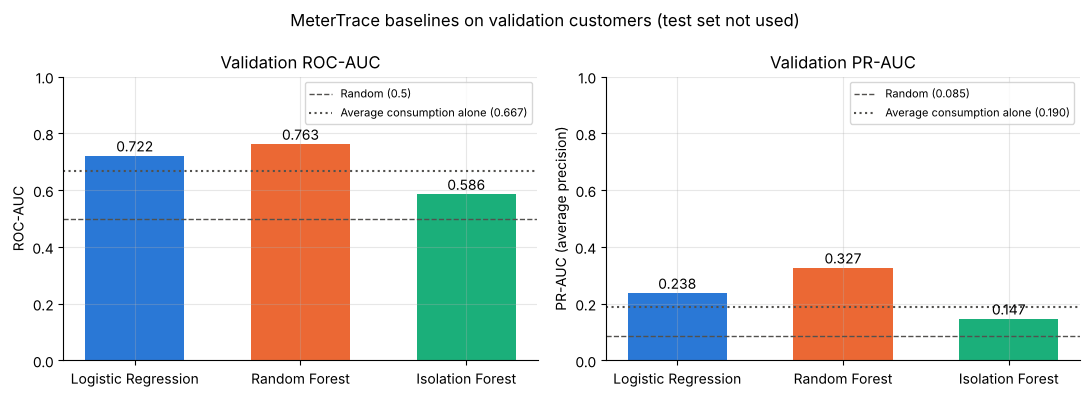

In [11]:
model_names = ["Logistic Regression", "Random Forest", "Isolation Forest"]
roc_values = validation_metrics.loc[model_names, "Validation ROC-AUC"].to_numpy()
pr_values = validation_metrics.loc[model_names, "Validation PR-AUC"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(model_names, roc_values, color=MODEL_COLORS, width=0.6)
axes[0].axhline(0.5, color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label="Random (0.5)")
axes[0].axhline(reference_auc, color=NEUTRAL_COLOR, linestyle=":", linewidth=1.5,
                label=f"Average consumption alone ({reference_auc:.3f})")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("Validation ROC-AUC")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].bar(model_names, pr_values, color=MODEL_COLORS, width=0.6)
axes[1].axhline(random_pr_auc, color=NEUTRAL_COLOR, linestyle="--", linewidth=1,
                label=f"Random ({random_pr_auc:.3f})")
axes[1].axhline(reference_pr_auc, color=NEUTRAL_COLOR, linestyle=":", linewidth=1.5,
                label=f"Average consumption alone ({reference_pr_auc:.3f})")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("PR-AUC (average precision)")
axes[1].set_title("Validation PR-AUC")
axes[1].legend(loc="upper right", fontsize=8)

for panel, values in zip(axes, [roc_values, pr_values]):
    for position, value in enumerate(values):
        panel.text(position, value + 0.015, f"{value:.3f}", ha="center")

fig.suptitle("MeterTrace baselines on validation customers (test set not used)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_validation_comparison.png", dpi=120)
plt.show()

**Summary of the validation comparison.**
- **Supervised branch:** Random Forest (0.7628 / 0.3268) is ahead of Logistic Regression (0.7216 / 0.2377).
  Both beat the "average consumption alone" reference on both metrics.
- **Unsupervised branch:** Isolation Forest (0.5863 / 0.1470) is above random but below the reference.
  Its fair comparison is the autoencoder in Notebook 05.
- **What PR-AUC tells us:** even the best model has a PR-AUC of about 0.33, so many normal customers are
  still mixed in among the highest-ranked ones. These are inspection **leads**, not proof of theft.
- **Training times** (see the table) are a few seconds at most, so all three models are lightweight.

These are **validation** results, used only for comparison. The final, reported numbers will come from the
test set in Notebook 06.

## 7. Save the models and the validation scores
- **Models** go to `models/` with `joblib`. This folder is git-ignored because a Random Forest file can be
  large; re-running this notebook re-creates identical models (fixed seeds).
- **Validation scores** for every customer, in the same row order as the feature and weekly files, go to
  `outputs/results/04_validation_scores.csv`. Notebook 06 will use them to choose thresholds.
- **No test predictions are saved.** Notebook 06 will load these models and score the test set once.

In [12]:
joblib.dump(logistic_regression, MODEL_DIR / "logistic_regression.joblib")
joblib.dump(random_forest, MODEL_DIR / "random_forest.joblib", compress=3)
joblib.dump(isolation_forest, MODEL_DIR / "isolation_forest.joblib", compress=3)

validation_scores = pd.DataFrame({
    LABEL_COLUMN: y_validation,
    "logistic_regression_probability": lr_validation_probability,
    "random_forest_probability": rf_validation_probability,
    "isolation_forest_anomaly_score": if_validation_score,
}, index=validation_table.index)
validation_scores.to_csv(RESULTS_DIR / "04_validation_scores.csv")

for path in sorted(MODEL_DIR.glob("*.joblib")):
    print(f"{path.relative_to(PROJECT_ROOT)}: {path.stat().st_size / 1e6:.1f} MB")
print("outputs/results/04_validation_scores.csv:", validation_scores.shape)

models/isolation_forest.joblib: 0.2 MB
models/logistic_regression.joblib: 0.0 MB
models/random_forest.joblib: 10.0 MB
outputs/results/04_validation_scores.csv: (6354, 4)


### Check that the saved models reload and give identical scores

In [13]:
reloaded_lr = joblib.load(MODEL_DIR / "logistic_regression.joblib")
reloaded_rf = joblib.load(MODEL_DIR / "random_forest.joblib")
reloaded_if = joblib.load(MODEL_DIR / "isolation_forest.joblib")

print("Logistic Regression identical:", np.allclose(reloaded_lr.predict_proba(X_validation)[:, 1], lr_validation_probability))
print("Random Forest identical:      ", np.allclose(reloaded_rf.predict_proba(X_validation)[:, 1], rf_validation_probability))
print("Isolation Forest identical:   ", np.allclose(-reloaded_if.score_samples(X_validation), if_validation_score))
print("Scores file row order matches features file:",
      bool((pd.read_csv(RESULTS_DIR / "04_validation_scores.csv", index_col=0).index == validation_table.index).all()))

Logistic Regression identical: True
Random Forest identical:       True
Isolation Forest identical:    True
Scores file row order matches features file: True


## What We Learned
Key ideas to be able to explain in the viva:

1. **Accuracy is misleading with imbalanced classes.** Predicting "normal" for every validation customer
   gives 91.50% accuracy and 0% recall. We therefore use ROC-AUC and PR-AUC, which measure how well
   theft customers are *ranked* above normal ones.
2. **PR-AUC has a different baseline from ROC-AUC.** A random ranking gives ROC-AUC 0.5 but PR-AUC equal
   to the theft share (about 0.085). Always compare a PR-AUC with that baseline, not with 0.5.
3. **Fit preprocessing inside a `Pipeline`.** Putting the `StandardScaler` inside the Logistic Regression
   pipeline guarantees it is fitted on training customers only and applied unchanged to validation.
4. **Class weights handle imbalance without changing the data.** `class_weight="balanced"` and
   `"balanced_subsample"` make each theft customer count more during training, instead of duplicating or
   deleting rows.
5. **Coefficients of correlated features must be read together.** `std_kwh` received a large positive
   weight and its close partner `max_kwh` a negative one. That is shared credit between overlapping
   features, not proof that a high maximum protects against theft.
6. **A training score can be perfect and still mean nothing.** Random Forest scored 1.0000 ROC-AUC on its
   own training customers but 0.7628 on validation. Only scores on unseen customers count.
7. **Unsupervised ≠ theft detector.** Isolation Forest, trained on normal customers without targets, finds
   *unusual* customers. That gave only 0.5863 ROC-AUC, because unusual and theft are not the same thing.
8. **Keep the test set locked.** We did not load the test file and did not choose thresholds. Model
   comparison used validation data only. The test set will be scored once, in Notebook 06.